<a href="https://colab.research.google.com/github/tanu100/MachineLearning/blob/main/Imputer/HandlingMissingValues.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Using SimpleImputer**


The SimpleImputer follows the standard Scikit-learn transformer API, meaning it has fit and transform methods.

fit(X): During the fit step, the imputer calculates the statistic (e.g., mean, median, mode) from the non-missing values in each column of the training data X. This learned statistic is stored internally.


transform(X): The transform step uses the statistics learned during fit to fill the missing values (marked as np.nan or another specified marker) in the input data X.


It's important to fit the imputer only on the training data and then use it to transform both the training and the test data. This prevents data leakage, ensuring that information from the test set doesn't influence the imputation values used for the training set.

**Imputation Strategies**


SimpleImputer supports several imputation strategies via the strategy parameter:

* **mean**: Replaces missing values using the mean along each column. Suitable only for numerical data. Can be sensitive to outliers.


* **median**: Replaces missing values using the median along each column. Also only for numerical data. Generally more effective against outliers than the mean.


* **most_frequent**: Replaces missing values using the mode (the most frequent value) along each column. Can be used with both numerical and categorical data.


* **constant**: Replaces missing values with a fixed value specified by the fill_value parameter. This can be useful if missing values have a specific meaning or if you want to use a placeholder like 0 or -1 for numerical data, or "Missing" for categorical data.

In [39]:
from sklearn.impute import SimpleImputer
import seaborn as sns

In [40]:
import pandas as pd
import numpy as np

data = {
    'age': [22, 25, 28, np.nan, 35, 42, 29, 31, np.nan, 45, 38, 26],

    'salary': [25000, 30000, 35000, 40000, np.nan, 80000,
               45000, 50000, 60000, 200000, np.nan, 32000],

    'experience': [1, 2, 4, 5, np.nan, 15, 6, 8, 10, 20, 12, np.nan],

    'education': ['UG', 'PG', 'UG', 'School', 'PG', np.nan,
                  'UG', 'PG', 'School', 'PG', np.nan, 'UG'],

    'gender': ['Male', 'Female', 'Male', 'Female', 'Male', 'Male',
               np.nan, 'Female', 'Male', 'Female', 'Male', np.nan],

    'city': ['Delhi', 'Mumbai', 'Delhi', 'Pune', 'Mumbai', 'Delhi',
             'Pune', np.nan, 'Delhi', 'Mumbai', 'Pune', 'Delhi'],

    'loan_approved': ['Yes', 'No', 'Yes', 'No', 'Yes', 'Yes',
                      'No', 'Yes', 'Yes', 'No', 'Yes', 'No']
}

df = pd.DataFrame(data)

df

,age,salary,experience,education,gender,city,loan_approved
0,22.0,25000.0,1.0,UG,Male,Delhi,Yes
1,25.0,30000.0,2.0,PG,Female,Mumbai,No
2,28.0,35000.0,4.0,UG,Male,Delhi,Yes
3,NaN,40000.0,5.0,School,Female,Pune,No
4,35.0,NaN,NaN,PG,Male,Mumbai,Yes
5,42.0,80000.0,15.0,NaN,Male,Delhi,Yes
6,29.0,45000.0,6.0,UG,NaN,Pune,No
7,31.0,50000.0,8.0,PG,Female,NaN,Yes
8,NaN,60000.0,10.0,School,Male,Delhi,Yes
9,45.0,200000.0,20.0,PG,Female,Mumbai,No


In [41]:
df.isna().sum()

,0
age,2
salary,2
experience,2
education,2
gender,2
city,1
loan_approved,0


<Axes: >

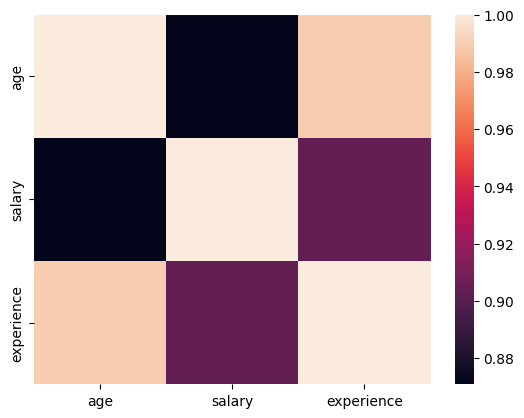

In [42]:
sns.heatmap(df.corr(numeric_only=True))

Index(['age', 'salary', 'experience'], dtype='object')


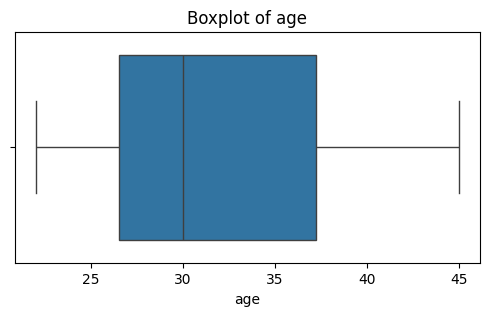

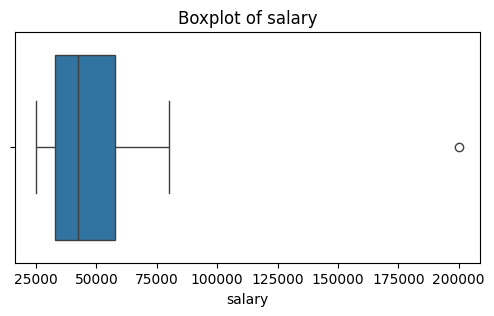

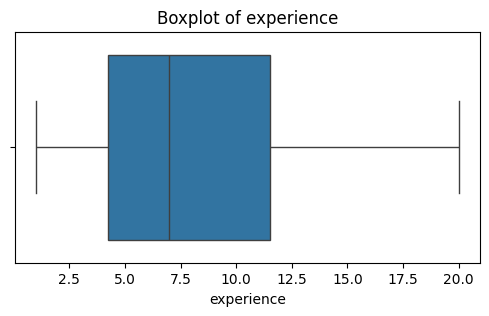

In [43]:
import matplotlib.pyplot as plt
cols=df.select_dtypes(include='number').columns
print(cols)

for i in cols:
  plt.figure(figsize=(6, 3))
  sns.boxplot(data=df, x=i)
  plt.title(f'Boxplot of {i}')
  plt.show()

In [44]:
imputer=SimpleImputer(strategy='mean')
df[['age', 'experience']]=imputer.fit_transform(df[['age', 'experience']])

In [45]:
imputer_median=SimpleImputer(strategy='median')
df[['salary']]=imputer_median.fit_transform(df[['salary']])

In [46]:
df

,age,salary,experience,education,gender,city,loan_approved
0,22.0,25000.0,1.0,UG,Male,Delhi,Yes
1,25.0,30000.0,2.0,PG,Female,Mumbai,No
2,28.0,35000.0,4.0,UG,Male,Delhi,Yes
3,32.1,40000.0,5.0,School,Female,Pune,No
4,35.0,42500.0,8.3,PG,Male,Mumbai,Yes
5,42.0,80000.0,15.0,NaN,Male,Delhi,Yes
6,29.0,45000.0,6.0,UG,NaN,Pune,No
7,31.0,50000.0,8.0,PG,Female,NaN,Yes
8,32.1,60000.0,10.0,School,Male,Delhi,Yes
9,45.0,200000.0,20.0,PG,Female,Mumbai,No


In [47]:
cat_cols=df.select_dtypes(include='object').columns

cat_imputer=SimpleImputer(strategy='most_frequent')

df[cat_cols]=cat_imputer.fit_transform(df[cat_cols])

In [48]:
df

,age,salary,experience,education,gender,city,loan_approved
0,22.0,25000.0,1.0,UG,Male,Delhi,Yes
1,25.0,30000.0,2.0,PG,Female,Mumbai,No
2,28.0,35000.0,4.0,UG,Male,Delhi,Yes
3,32.1,40000.0,5.0,School,Female,Pune,No
4,35.0,42500.0,8.3,PG,Male,Mumbai,Yes
5,42.0,80000.0,15.0,PG,Male,Delhi,Yes
6,29.0,45000.0,6.0,UG,Male,Pune,No
7,31.0,50000.0,8.0,PG,Female,Delhi,Yes
8,32.1,60000.0,10.0,School,Male,Delhi,Yes
9,45.0,200000.0,20.0,PG,Female,Mumbai,No


In [49]:
df.isna().sum()

,0
age,0
salary,0
experience,0
education,0
gender,0
city,0
loan_approved,0
